# BAX final prediction with an artificial 2D charge constraint

This MWE compares `get_bax_mean_prediction()` with the general
`get_constrained_mean_prediction()` helper in `bax_algorithms.utils`.
Both optimize the same virtual alignment objective using fitted GP means.

The artificial charge depends **only on the two tuning coordinates, x and y**.
A small elliptical region near good alignment has insufficient charge.
The field is used only for the virtual alignment measurement; it does not enter
the charge function or the definition of the excluded region.

Run all cells with this repository and its dependencies installed. The notebook
works when started in either the repository root or `examples/`.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from xopt import Xopt
from xopt.evaluator import Evaluator
from xopt.generators.bayesian.bax_generator import BaxGenerator
from xopt.vocs import VOCS

from bax_algorithms.pathwise.optimize import DifferentialEvolution
from bax_algorithms.solenoid_alignment import PathwiseSolenoidAlignment
from bax_algorithms.utils import (
    get_bax_mean_prediction,
    get_constrained_mean_prediction,
)

torch.manual_seed(1)
np.random.seed(1)
torch.set_num_threads(1)

## Synthetic measurement and charge

The centroids are $c_x=(x-0.1)b$ and $c_y=1.3(y+0.05)b$, where $b$ is the
measurement field. The alignment objective is the sum of their standard
deviations over a field scan; its true minimum is at $(0.1,-0.05)$.

Artificial charge in pC is

$$Q(x,y)=100-80\exp\left[-\frac12\left(
\frac{(x-0.18)^2}{0.22^2}+\frac{(y+0.05)^2}{0.25^2}\right)\right].$$

We require $Q\ge60$ pC. The excluded ellipse occupies about 6% of the tuning
square and includes the unconstrained optimum. Nothing in $Q$ depends on field.

In [2]:
CHARGE_THRESHOLD = 60.0


def charge(x, y):
    radius_squared = ((x - 0.18) / 0.22) ** 2 + ((y + 0.05) / 0.25) ** 2
    return 100.0 - 80.0 * np.exp(-0.5 * radius_squared)


def measure(inputs):
    x, y, field = inputs["x"], inputs["y"], inputs["field"]
    return {
        "cx": (x - 0.1) * field,
        "cy": 1.3 * (y + 0.05) * field,
        "charge": charge(x, y),
    }


vocs = VOCS(
    variables={"x": [-1.0, 1.0], "y": [-1.0, 1.0], "field": [-1.0, 1.0]},
    observables=["cx", "cy"],
    constraints={"charge": ["GREATER_THAN", CHARGE_THRESHOLD]},
)
algorithm = PathwiseSolenoidAlignment(
    x_key="cx",
    y_key="cy",
    meas_dim=vocs.variable_names.index("field"),
    observable_names_ordered=["cx", "cy"],
    n_steps_measurement_param=5,
    n_samples=2,
)
generator = BaxGenerator(vocs=vocs, algorithm=algorithm)
generator.gp_constructor.use_low_noise_prior = True
X = Xopt(vocs=vocs, generator=generator, evaluator=Evaluator(function=measure))

# A deterministic grid supplies training data; no acquisition loop is needed
# to isolate the behavior of the final-prediction helpers.
training_inputs = pd.DataFrame(
    [
        {"x": x, "y": y, "field": field}
        for x in np.linspace(-1, 1, 11)
        for y in np.linspace(-1, 1, 11)
        for field in [-1.0, 0.0, 1.0]
    ]
)
X.evaluate_data(training_inputs)
print(f"Training observations: {len(X.data)}")
print("Model input order:", vocs.variable_names)
assert (
    measure({"x": 0.1, "y": -0.05, "field": -1})["charge"]
    == measure({"x": 0.1, "y": -0.05, "field": 1})["charge"]
)

Training observations: 363
Model input order: ['x', 'y', 'field']


## Compare the two final predictions

`get_constrained_mean_prediction()` reads every constraint from VOCS, with Xopt's
output ordering and inequality directions. No charge name, alignment algorithm,
or field scan is hard-coded into that helper.

Here `kappa=2` requires the charge GP's lower confidence bound
`mean - 2 * std >= 60`. Use `kappa=0` for posterior-mean feasibility alone.
This margin is not a guarantee of physical safety.

As with the existing optimizer, dimensions outside the tuning subset are filled
with their bounds' midpoints for the constraint query. Here that is `field=0`;
the true constraint is independent of field. A general `constraint_points`
callback is available if an application needs checks at other inputs.

In [3]:
mean_optimizer = DifferentialEvolution(popsize=30, maxiter=150)
original = get_bax_mean_prediction(X.generator, mean_optimizer)
KAPPA = 2.0
constrained = get_constrained_mean_prediction(X.generator, mean_optimizer, kappa=KAPPA)

bounds = X.generator._get_optimization_bounds()
tuning_indices = algorithm._get_optimization_indeces(bounds)
tuning_names = [vocs.variable_names[i] for i in tuning_indices]
assert tuning_names == ["x", "y"]
charge_index = vocs.output_names.index("charge")
mean_functions = [
    (
        lambda z,
        m=X.generator.model.subset_output([vocs.output_names.index(name)]): m.posterior(
            z
        ).mean
    )
    for name in algorithm.observable_names_ordered
]


def diagnostics(point):
    full = bounds.mean(dim=0).repeat(len(point), 1)
    full[:, tuning_indices] = point
    with torch.no_grad():
        posterior = X.generator.model.posterior(full)
        mu = posterior.mean[..., charge_index].item()
        sigma = posterior.variance[..., charge_index].clamp_min(0).sqrt().item()
        objective = algorithm.evaluate_virtual_objective(
            mean_functions, full, bounds
        ).item()
    x, y = point[0].tolist()
    return {
        "x": x,
        "y": y,
        "predicted misalignment": objective,
        "charge mean (pC)": mu,
        "charge lower bound (pC)": mu - KAPPA * sigma,
        "true charge (pC)": charge(x, y),
    }


results = pd.DataFrame(
    [diagnostics(original), diagnostics(constrained)],
    index=["Existing helper", "Constraint-aware helper"],
)
display(results.round(5))
assert results.loc["Existing helper", "charge mean (pC)"] < CHARGE_THRESHOLD
assert results.loc["Existing helper", "true charge (pC)"] < CHARGE_THRESHOLD
assert (
    results.loc["Constraint-aware helper", "charge lower bound (pC)"]
    >= CHARGE_THRESHOLD
)
assert results.loc["Constraint-aware helper", "true charge (pC)"] >= CHARGE_THRESHOLD
print(
    "PASS: existing helper violates the charge constraint; constrained helper satisfies it."
)

,x,y,predicted misalignment,charge mean (pC),charge lower bound (pC),true charge (pC)
Existing helper,0.10040,-0.05021,0.00000,25.22454,25.05568,25.06837
Constraint-aware helper,-0.08017,-0.05026,0.15414,60.17362,60.00706,60.24339


PASS: existing helper violates the charge constraint; constrained helper satisfies it.


## Visualize the excluded region and both predictions

The left panel shows the artificial charge and its exact forbidden region. The
right panel shows the alignment objective built from GP means. The solid red
boundary is the true 60 pC charge contour; the dashed blue boundary is the
constraint used by the new helper (`charge mean - 2σ = 60`, evaluated at field=0).
Both predicted tuning points appear on both panels.

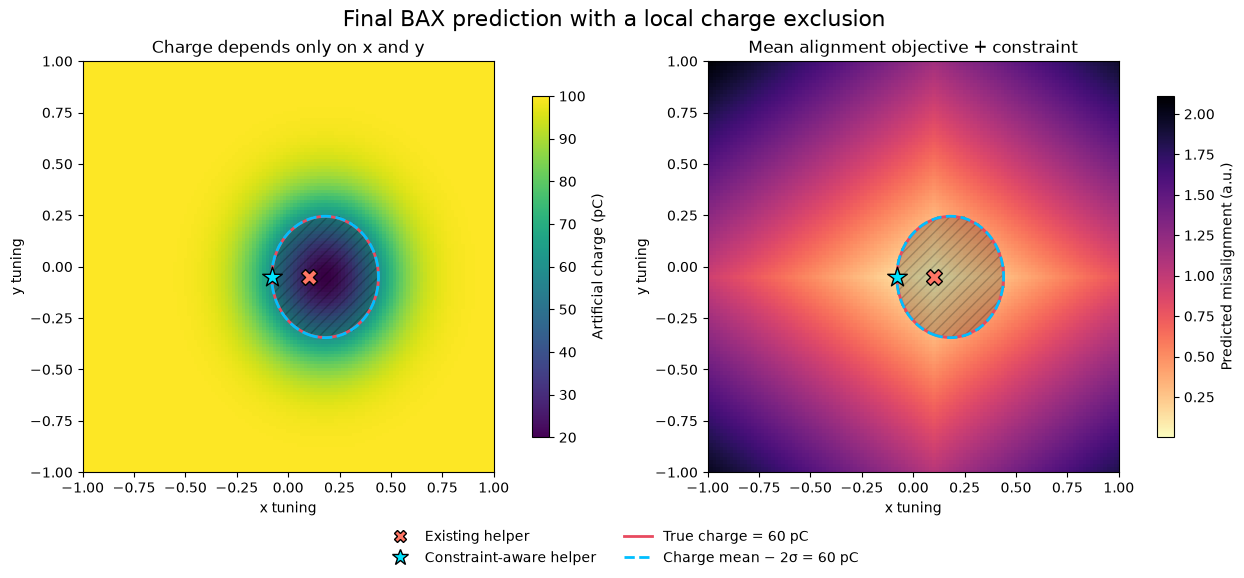

In [4]:
grid = np.linspace(-1, 1, 121)
xx, yy = np.meshgrid(grid, grid)
true_charge = charge(xx, yy)
xy = torch.tensor(np.column_stack([xx.ravel(), yy.ravel()]), dtype=bounds.dtype)
full = bounds.mean(dim=0).repeat(len(xy), 1)
full[:, tuning_indices] = xy
objective_parts, charge_bound_parts = [], []
with torch.no_grad():
    for chunk in full.split(256):
        objective_parts.append(
            algorithm.evaluate_virtual_objective(mean_functions, chunk, bounds).reshape(
                -1
            )
        )
        posterior = X.generator.model.posterior(chunk)
        charge_bound_parts.append(
            posterior.mean[..., charge_index]
            - KAPPA * posterior.variance[..., charge_index].clamp_min(0).sqrt()
        )
objective_map = torch.cat(objective_parts).numpy().reshape(xx.shape)
charge_bound_map = torch.cat(charge_bound_parts).numpy().reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.7), layout="constrained")
fig.suptitle("Final BAX prediction with a local charge exclusion", fontsize=16)
left = axes[0].pcolormesh(
    xx, yy, true_charge, shading="auto", cmap="viridis", vmin=20, vmax=100
)
fig.colorbar(left, ax=axes[0], label="Artificial charge (pC)", shrink=0.83)
axes[0].set_title("Charge depends only on x and y")
right = axes[1].pcolormesh(xx, yy, objective_map, shading="auto", cmap="magma_r")
fig.colorbar(right, ax=axes[1], label="Predicted misalignment (a.u.)", shrink=0.83)
axes[1].set_title("Mean alignment objective + constraint")

for ax in axes:
    ax.contourf(
        xx,
        yy,
        true_charge < CHARGE_THRESHOLD,
        levels=[0.5, 1.5],
        colors="none",
        hatches=["///"],
        alpha=0.2,
    )
    ax.contour(
        xx, yy, true_charge, levels=[CHARGE_THRESHOLD], colors=["#e84a5f"], linewidths=2
    )
    ax.contour(
        xx,
        yy,
        charge_bound_map,
        levels=[CHARGE_THRESHOLD],
        colors=["#00bfff"],
        linewidths=2,
        linestyles="--",
    )
    ax.scatter(
        *original[0].tolist(),
        marker="X",
        s=130,
        color="#ff7665",
        edgecolor="black",
        zorder=5,
    )
    ax.scatter(
        *constrained[0].tolist(),
        marker="*",
        s=220,
        color="#00e5ff",
        edgecolor="black",
        zorder=6,
    )
    ax.set(
        xlabel="x tuning", ylabel="y tuning", xlim=(-1, 1), ylim=(-1, 1), aspect="equal"
    )

handles = [
    Line2D(
        [],
        [],
        marker="X",
        color="none",
        markerfacecolor="#ff7665",
        markeredgecolor="black",
        markersize=9,
        label="Existing helper",
    ),
    Line2D(
        [],
        [],
        marker="*",
        color="none",
        markerfacecolor="#00e5ff",
        markeredgecolor="black",
        markersize=12,
        label="Constraint-aware helper",
    ),
    Line2D([], [], color="#e84a5f", linewidth=2, label="True charge = 60 pC"),
    Line2D(
        [],
        [],
        color="#00bfff",
        linestyle="--",
        linewidth=2,
        label="Charge mean − 2σ = 60 pC",
    ),
]
fig.legend(handles=handles, loc="outside lower center", ncol=2, frameon=False)